# Entrega 2: YOLO customizado, YOLO padrão e CNN do zero

FarmTech Solutions · Fase 6 · Capítulo 1

Grupo: Karina Queiroz de Gennaro (RM570928), Luis Felipe Bardi (RM569479) e Beatriz de Oliveira
Ossola Ribeiro (RM570190)

Na Entrega 1 treinamos o YOLOv5s para detectar crachás e seringas. Aqui usamos a mesma base para
comparar três abordagens:

| Abordagem | O que faz | Treino |
|---|---|---|
| YOLO customizado | detecta `cracha` e `seringa` com caixas | reaproveita o `best.pt` da Entrega 1 |
| YOLO padrão | YOLOv5s com os pesos do COCO, sem nenhum ajuste | nenhum |
| CNN do zero | classifica a imagem inteira como `cracha` ou `seringa` | treinada neste notebook |

Entendemos o "YOLO tradicional" do enunciado como o YOLOv5s pré-treinado no COCO, usado como vem.
Como é a mesma rede de onde partimos na Entrega 1, a comparação mostra o que a customização
acrescenta.

Durante a análise encontramos erros nos rótulos de treino da Entrega 1. Por isso, também treinamos
de novo o YOLO customizado com os rótulos corrigidos (seção 3.1).

Comparamos as abordagens nas mesmas imagens de teste e na mesma GPU, pelos critérios do enunciado:
facilidade de uso e integração, precisão, tempo de treinamento e tempo de inferência.

### Como executar

1. No Colab, escolha a GPU T4 em Ambiente de execução > Alterar o tipo de ambiente de execução.
2. A base fica na pasta [FarmTech_dataset](https://drive.google.com/drive/folders/1-6sfF80J6KI_1Yia5Elcm9v7Hu0cIwjI?usp=sharing) do Google Drive. Se ela não aparecer no
   seu Meu Drive, abra o link e adicione um atalho na raiz (Organizar > Adicionar atalho).
3. Use Ambiente de execução > Executar tudo. O notebook baixa o YOLOv5 e o `best.pt` da Entrega 1
   direto do GitHub.

## 1. Ambiente

Montamos o Google Drive e definimos as pastas da base e de trabalho. Fora do Colab, essas pastas
podem ser trocadas pelas variáveis de ambiente `FARMTECH_DATA` e `FARMTECH_WORK`.

In [1]:
import os
import random
import shutil
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/FarmTech_dataset")
    WORK_DIR = Path("/content")
else:
    DATA_DIR = Path(os.environ.get("FARMTECH_DATA", "../data/FarmTech_dataset"))
    WORK_DIR = Path(os.environ.get("FARMTECH_WORK", "/tmp/farmtech_fase6"))

assert DATA_DIR.exists(), f"Dataset not found at {DATA_DIR}"

WORK_DIR.mkdir(parents=True, exist_ok=True)
os.environ["WANDB_MODE"] = "disabled"

print("Dataset:", DATA_DIR)

Mounted at /content/drive
Dataset: /content/drive/MyDrive/FarmTech_dataset


Baixamos o repositório do YOLOv5, o mesmo da Entrega 1, e os pesos `best.pt` publicados no GitHub
do grupo. Os pesos do YOLO padrão (`yolov5s.pt`) são baixados automaticamente na primeira vez que
o modelo é carregado.

In [2]:
YOLOV5_DIR = WORK_DIR / "yolov5"

if not YOLOV5_DIR.exists():
    !git clone --depth 1 -q https://github.com/ultralytics/yolov5 {YOLOV5_DIR}

if IN_COLAB:
    !pip install -q -r {YOLOV5_DIR}/requirements.txt

BEST_PT_URL = (
    "https://github.com/lfbardi-don/TEMPLATE-TIAO-2026/raw/main/"
    "1TIAO/FASE6/NOME-DA-ATIVIDADE-APRESENTADA-NO-PORTAL/src/best.pt"
)

if Path("best.pt").exists():
    ORIGINAL_WEIGHTS = Path("best.pt")
else:
    ORIGINAL_WEIGHTS = WORK_DIR / "best_entrega1.pt"

    if not ORIGINAL_WEIGHTS.exists():
        urllib.request.urlretrieve(BEST_PT_URL, ORIGINAL_WEIGHTS)

COCO_WEIGHTS = WORK_DIR / "yolov5s.pt"

print("Entrega 1 weights:", ORIGINAL_WEIGHTS)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.6 MB/s eta 0:00:00
Entrega 1 weights: /content/best_entrega1.pt


Importamos as bibliotecas e fixamos as sementes aleatórias, para que o resultado se repita a cada
execução.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from torchvision import transforms

SEED = 42
CLASSES = ["cracha", "seringa"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
YOLO_DEVICE = "0" if DEVICE == "cuda" else "cpu"
DEVICE_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"

print(f"Device: {DEVICE_NAME} | PyTorch {torch.__version__}")

Device: Tesla T4 | PyTorch 2.11.0+cu130


## 2. Base de dados

A base é a mesma da Entrega 1, já dividida em `train`, `val` e `test`. A classe de cada imagem
está no começo do nome do arquivo (`cracha_37.jpg`, `seringa_45.jpg`).

Cada abordagem precisa de um tipo de rótulo diferente. O YOLO customizado precisa de uma caixa por
objeto, desenhada no Make Sense e salva em `labels/*.txt`. O YOLO padrão não precisa de nenhum. A
CNN só precisa saber a classe da imagem, que tiramos do nome do arquivo.

A tabela conta, para cada divisão e classe:

- as imagens e as que abrem sem erro;
- as imagens com caixa e o total de caixas;
- as caixas com o número de classe errado (`wrong_class_boxes`). No `data.yaml`, 0 é `cracha` e 1
  é `seringa`.

In [4]:
def load_image(path):
    try:
        with Image.open(path) as image:
            return image.convert("RGB")
    except Exception:
        return None


def class_from_name(path):
    for name in CLASSES:
        if path.stem.lower().startswith(name):
            return name

    return None


def read_boxes(label_path):
    if not label_path.exists():
        return []

    lines = label_path.read_text().splitlines()
    return [line.split() for line in lines if line.strip()]


rows = []

for split in ["train", "val", "test"]:
    for path in sorted((DATA_DIR / split / "images").iterdir()):
        label = class_from_name(path)

        if not path.is_file() or label is None:
            continue

        boxes = read_boxes(DATA_DIR / split / "labels" / f"{path.stem}.txt")
        expected_id = str(CLASSES.index(label))

        rows.append({
            "split": split,
            "file": path.name,
            "path": path,
            "label": label,
            "readable": load_image(path) is not None,
            "boxes": len(boxes),
            "wrong_class_boxes": sum(box[0] != expected_id for box in boxes),
        })

dataset = pd.DataFrame(rows)

summary = dataset.groupby(["split", "label"]).agg(
    images=("file", "size"),
    readable=("readable", "sum"),
    with_box=("boxes", lambda boxes: (boxes > 0).sum()),
    boxes=("boxes", "sum"),
    wrong_class_boxes=("wrong_class_boxes", "sum"),
)

display(summary.reindex(["train", "val", "test"], level=0))

dataset = dataset[dataset.readable].reset_index(drop=True)

images  readable  with_box  boxes  wrong_class_boxes
split label                                                        
train cracha       80        80        78     78                 31
      seringa      81        81        32     32                 32
val   cracha       10        10        10     10                  0
      seringa      10        10         4      4                  0
test  cracha       10        10        10     10                  0
      seringa      11        11         4      4                  0

No treino, 31 caixas de crachá estão com o número da seringa, e as 32 caixas de seringa estão com
o número do crachá. Além disso, 49 das 81 seringas de treino não têm caixa. Validação e teste estão
corretos.

Conferindo a pasta da base, as seringas novas têm rótulos, mas os arquivos `.txt` ficaram com o
nome original da imagem (por exemplo, `download (12).txt`). Por isso não foram associados às
imagens renomeadas.

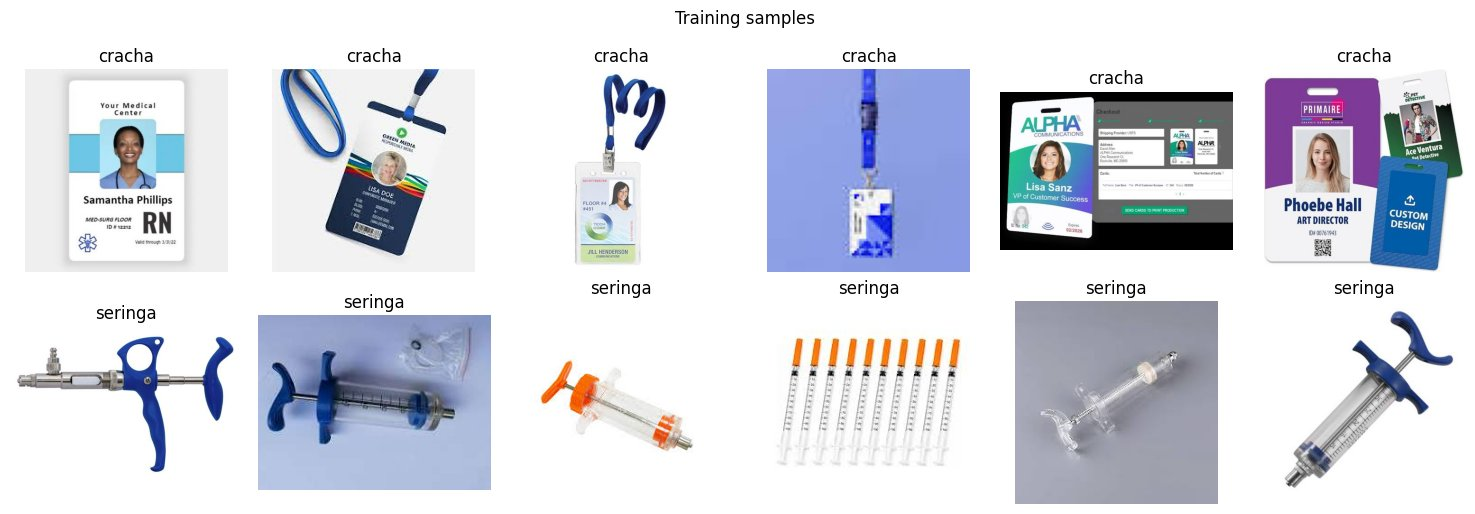

In [5]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))

for row_axes, label in zip(axes, CLASSES):
    sample = dataset[(dataset.split == "train") & (dataset.label == label)].sample(6, random_state=SEED)

    for ax, path in zip(row_axes, sample.path):
        ax.imshow(load_image(path))
        ax.set_title(label)
        ax.axis("off")

plt.suptitle("Training samples")
plt.tight_layout()
plt.show()

### Como medimos

As três abordagens respondem à mesma pergunta: qual objeto aparece na imagem?

- **Resposta do YOLO:** a classe da detecção com maior confiança, com o limiar de 0,25 que o
  `detect.py` usou na Entrega 1. Quando ele não detecta nada, a resposta é `none`, que conta como
  erro.
- **Resposta da CNN:** a classe de maior probabilidade.
- **Tempo de inferência:** a mediana por imagem, uma imagem por vez. Ela inclui o
  pré-processamento, a rede e, no YOLO, o NMS, a etapa que remove caixas repetidas. Antes de medir,
  rodamos uma imagem para aquecer a GPU, e repetimos o teste três vezes.

As funções abaixo são usadas em todas as abordagens. Elas medem o tempo, calculam as métricas e
mostram as imagens de teste com a resposta de cada modelo: verde quando ele acerta, vermelho quando
erra.

In [6]:
test = dataset[dataset.split == "test"].reset_index(drop=True)
test_images = [load_image(path) for path in test.path]
test_labels = list(test.label)

print(len(test), "test images:", test.label.value_counts().to_dict())


def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


def timed_predictions(predict, images, repeats=3):
    predict(images[0])
    times = []

    for _ in range(repeats):
        outputs = []

        for image in images:
            sync()
            start = time.perf_counter()
            outputs.append(predict(image))
            sync()
            times.append((time.perf_counter() - start) * 1000)

    return outputs, float(np.median(times))


def evaluate(name, predictions, inference_ms):
    y_true = np.array(test_labels)
    y_pred = np.array(predictions)

    return {
        "approach": name,
        "accuracy": (y_true == y_pred).mean(),
        "recall_cracha": (y_pred[y_true == "cracha"] == "cracha").mean(),
        "recall_seringa": (y_pred[y_true == "seringa"] == "seringa").mean(),
        "no_answer": (y_pred == "none").mean(),
        "inference_ms": inference_ms,
    }


def show_predictions(predictions, title, detections=None, captions=None, cols=7):
    n_rows = int(np.ceil(len(test_images) / cols))
    fig, axes = plt.subplots(n_rows, cols, figsize=(2.6 * cols, 3.0 * n_rows))

    for i, ax in enumerate(axes.flat):
        ax.axis("off")

        if i >= len(test_images):
            continue

        ax.imshow(test_images[i])

        for name, conf, (x1, y1, x2, y2) in (detections[i] if detections else []):
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2, color="yellow"))
            ax.text(x1, y1, f"{name} {conf:.2f}", fontsize=7, backgroundcolor="yellow")

        caption = captions[i] if captions else predictions[i]
        color = "green" if predictions[i] == test_labels[i] else "red"
        ax.set_title(f"{test.file[i]}\n{caption}", fontsize=8, color=color)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

21 test images: {'seringa': 11, 'cracha': 10}


## 3. YOLO customizado (Entrega 1)

Carregamos o `best.pt` publicado na Entrega 1: o YOLOv5s treinado a partir dos pesos do COCO por
50 épocas. Segundo o log da Entrega 1, o treino levou 0,047 h, cerca de 2,8 minutos numa T4.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


,accuracy,recall_cracha,recall_seringa,no_answer,inference_ms
approach,,,,,
Custom YOLO (Entrega 1),0.143,0.3,0.0,0.714,14.186


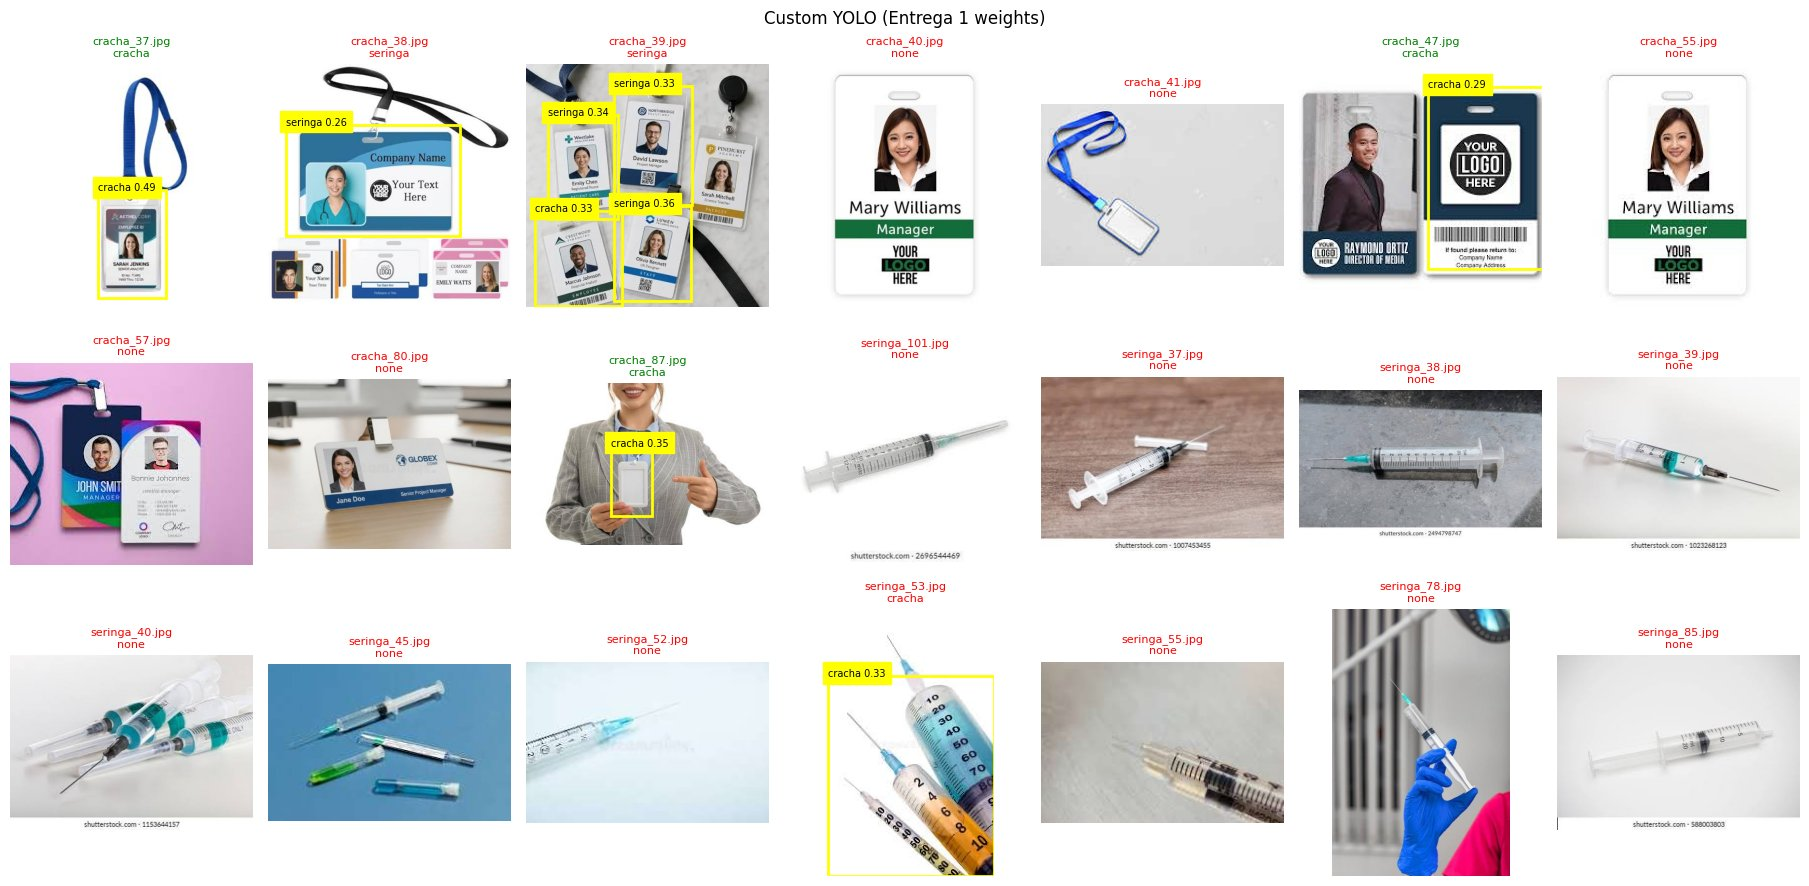

In [7]:
def load_yolo(weights):
    model = torch.hub.load(
        str(YOLOV5_DIR),
        "custom",
        path=str(weights),
        source="local",
        _verbose=False,
        device=YOLO_DEVICE,
    )
    model.conf = 0.25
    return model


def detect(model, image):
    result = model(image, size=640)

    return [
        (model.names[int(cls)], conf, (x1, y1, x2, y2))
        for x1, y1, x2, y2, conf, cls in result.xyxy[0].tolist()
    ]


def top_class(detections):
    if not detections:
        return "none"

    return max(detections, key=lambda d: d[1])[0]


original_yolo = load_yolo(ORIGINAL_WEIGHTS)

original_dets, original_ms = timed_predictions(lambda image: detect(original_yolo, image), test_images)
original_preds = [top_class(d) for d in original_dets]

results = [evaluate("Custom YOLO (Entrega 1)", original_preds, original_ms)]

display(pd.DataFrame(results).set_index("approach").round(3))
show_predictions(original_preds, "Custom YOLO (Entrega 1 weights)", detections=original_dets)

Para um detector, a métrica mais usada é o mAP. Ela só conta um acerto quando a caixa prevista
cobre a caixa real (IoU ≥ 0,5) e a classe está certa.

Rodamos o `val.py` do YOLOv5 no conjunto de teste a partir de uma cópia local. O `val.py` grava um
arquivo de cache ao lado dos rótulos, e assim nada é escrito na pasta compartilhada do Drive.

In [8]:
test_copy = WORK_DIR / "farmtech_test"
shutil.rmtree(test_copy, ignore_errors=True)
shutil.copytree(DATA_DIR / "test", test_copy / "test")

test_yaml = WORK_DIR / "farmtech_test.yaml"
test_yaml.write_text(
    f"path: {test_copy}\n"
    "train: test/images\n"
    "val: test/images\n"
    "test: test/images\n"
    f"names: {CLASSES}\n"
)


def run_yolo(script, *args):
    result = subprocess.run(
        [sys.executable, str(YOLOV5_DIR / script), *map(str, args)],
        capture_output=True,
        text=True,
    )
    log = (result.stdout + "\n" + result.stderr).splitlines()

    assert result.returncode == 0, "\n".join(log[-40:])
    return log


def print_metrics(log):
    columns = ["Images", "Instances", "P", "R", "mAP50", "mAP50-95"]
    print(f"{'Class':>22}" + "".join(f"{col:>11}" for col in columns))

    for line in log:
        if line.strip().startswith(("all", "cracha", "seringa")):
            print(line)


def test_map(weights, run_name):
    log = run_yolo(
        "val.py",
        "--weights", weights,
        "--data", test_yaml,
        "--task", "test",
        "--img", 640,
        "--batch-size", 8,
        "--device", YOLO_DEVICE,
        "--project", WORK_DIR / "runs",
        "--name", run_name,
        "--exist-ok",
    )
    print_metrics(log)


test_map(ORIGINAL_WEIGHTS, "test_original")

                 Class     Images  Instances          P          R      mAP50   mAP50-95
                   all         21         14      0.186       0.35      0.206      0.107
                cracha         21         10      0.372        0.7      0.394      0.208
               seringa         21          4          0          0     0.0168    0.00525


Com os pesos da Entrega 1, o YOLO acerta 3 das 21 imagens (14%). Em 15 delas (71%) ele não
detecta nada, nenhuma seringa é reconhecida e 2 crachás aparecem como seringa. O mAP50 no teste
fica em 0,21: 0,39 no crachá e 0,02 na seringa. É o que se espera de um modelo treinado com as
classes trocadas.

### 3.1 YOLO customizado com rótulos corrigidos

Para saber quanto do resultado acima vem dos rótulos, montamos uma cópia corrigida da base e
repetimos o treino da Entrega 1: YOLOv5s a partir do COCO, imagens de 640 px, lote de 16 e 50
épocas.

- **Classe:** na cópia, o número da classe de cada caixa vem do nome do arquivo. Isso funciona
  porque cada imagem tem uma única caixa.
- **Imagens sem caixa:** ficam de fora, já que o YOLO as trataria como fundo.
- **Pasta original:** a do Drive não é alterada.

In [9]:
fixed_dir = WORK_DIR / "farmtech_fixed"
shutil.rmtree(fixed_dir, ignore_errors=True)

for row in dataset[dataset.boxes > 0].itertuples():
    image_dir = fixed_dir / row.split / "images"
    label_dir = fixed_dir / row.split / "labels"

    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(row.path, image_dir / row.file)

    stem = Path(row.file).stem
    boxes = read_boxes(DATA_DIR / row.split / "labels" / f"{stem}.txt")
    class_id = str(CLASSES.index(row.label))
    fixed_lines = [" ".join([class_id, *box[1:]]) for box in boxes]

    (label_dir / f"{stem}.txt").write_text("\n".join(fixed_lines) + "\n")

fixed_yaml = WORK_DIR / "farmtech_fixed.yaml"
fixed_yaml.write_text(
    f"path: {fixed_dir}\n"
    "train: train/images\n"
    "val: val/images\n"
    "test: test/images\n"
    f"names: {CLASSES}\n"
)

images_per_split = dataset[dataset.boxes > 0].groupby(["split", "label"]).size().unstack()
images_per_split.reindex(["train", "val", "test"])

label,cracha,seringa
split,,
train,78,32
val,10,4
test,10,4


O treino leva cerca de 3 minutos numa T4. Para não encher o notebook com o log de cada época,
mostramos só o resumo final.

In [10]:
YOLO_EPOCHS = int(os.environ.get("FARMTECH_YOLO_EPOCHS", 50))

print(f"Training for {YOLO_EPOCHS} epochs...")

sync()
start = time.perf_counter()

train_log = run_yolo(
    "train.py",
    "--img", 640,
    "--batch-size", 16,
    "--epochs", YOLO_EPOCHS,
    "--data", fixed_yaml,
    "--weights", COCO_WEIGHTS,
    "--cache", "ram",
    "--workers", 2,
    "--device", YOLO_DEVICE,
    "--seed", 0,
    "--project", WORK_DIR / "runs",
    "--name", "fixed_labels",
    "--exist-ok",
)

fixed_train_seconds = time.perf_counter() - start
FIXED_WEIGHTS = WORK_DIR / "runs" / "fixed_labels" / "weights" / "best.pt"

end_of_training = next(i for i, line in enumerate(train_log) if "epochs completed" in line)

print(train_log[end_of_training])
print_metrics(train_log[end_of_training:])
print(f"Cell time: {fixed_train_seconds / 60:.1f} min ({DEVICE_NAME})")

Training for 50 epochs...
50 epochs completed in 0.035 hours.
                 Class     Images  Instances          P          R      mAP50   mAP50-95
                   all         14         14       0.86       0.74      0.815      0.464
                cracha         14         10      0.721      0.775      0.774       0.29
               seringa         14          4          1      0.705      0.856      0.639
Cell time: 2.6 min (Tesla T4)


,accuracy,recall_cracha,recall_seringa,no_answer,inference_ms
approach,,,,,
Custom YOLO (Entrega 1),0.143,0.3,0.000,0.714,14.186
Custom YOLO (fixed labels),0.524,0.7,0.364,0.429,10.461


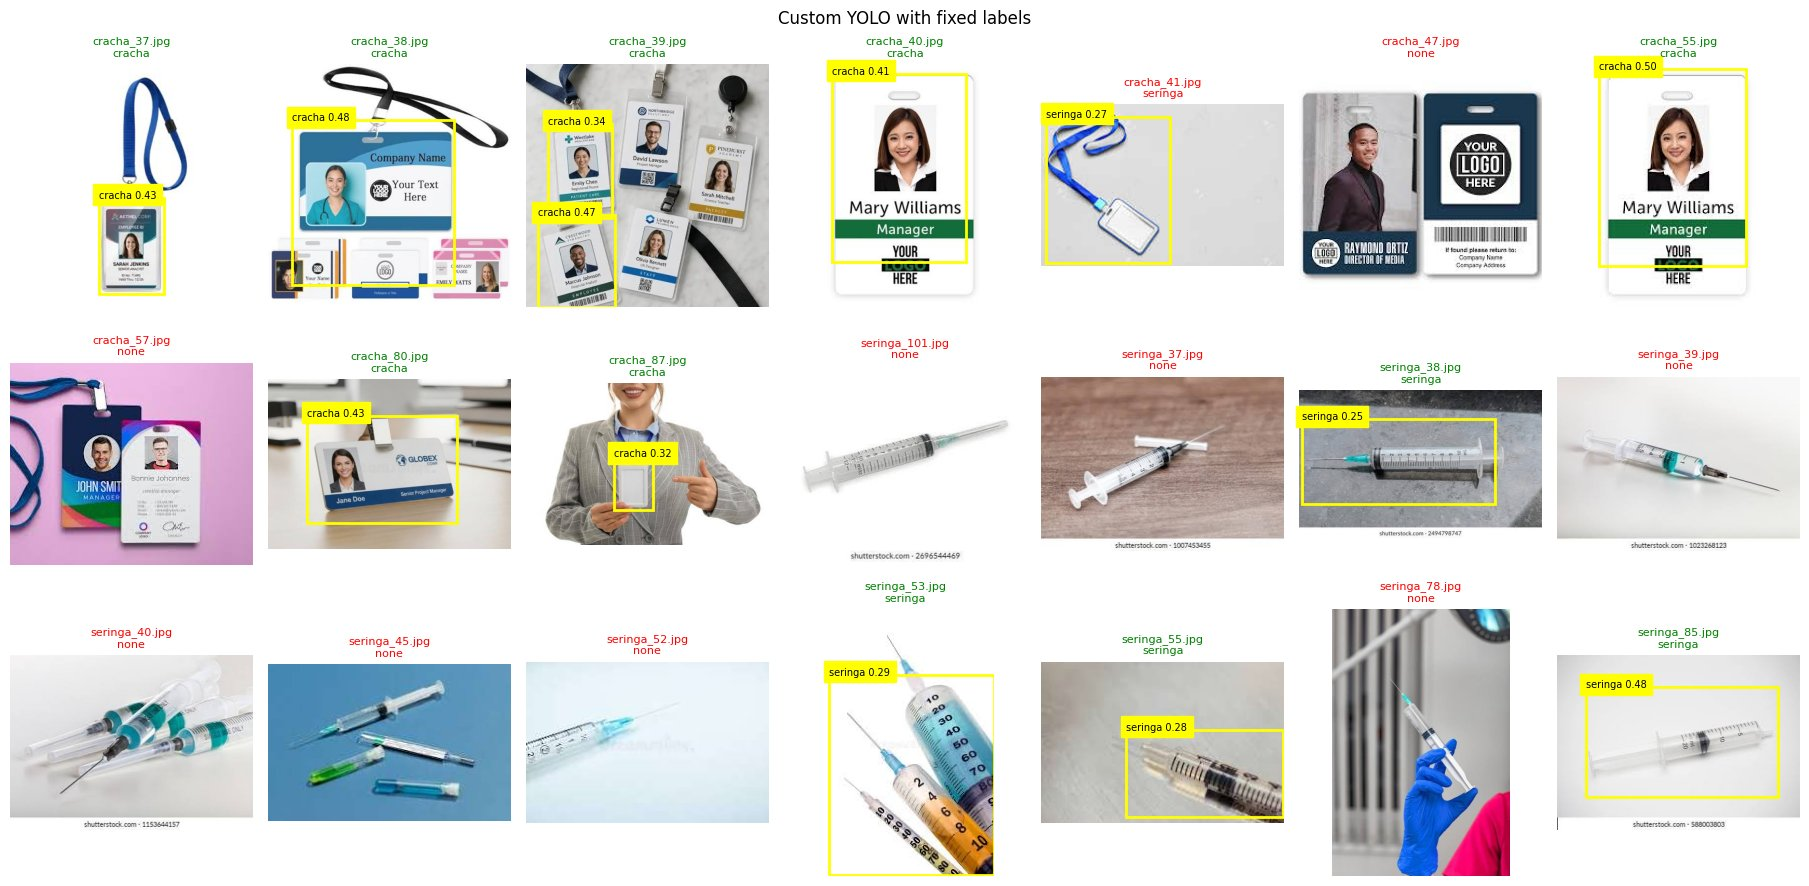

                 Class     Images  Instances          P          R      mAP50   mAP50-95
                   all         21         14       0.48      0.624      0.504      0.263
                cracha         21         10      0.532        0.5       0.66       0.32
               seringa         21          4      0.428      0.747      0.348      0.206


In [11]:
fixed_yolo = load_yolo(FIXED_WEIGHTS)

fixed_dets, fixed_ms = timed_predictions(lambda image: detect(fixed_yolo, image), test_images)
fixed_preds = [top_class(d) for d in fixed_dets]

results.append(evaluate("Custom YOLO (fixed labels)", fixed_preds, fixed_ms))

display(pd.DataFrame(results).set_index("approach").round(3))
show_predictions(fixed_preds, "Custom YOLO with fixed labels", detections=fixed_dets)
test_map(FIXED_WEIGHTS, "test_fixed")

Só corrigindo os rótulos, com o mesmo modelo e as mesmas 50 épocas, a acurácia sobe de 14% para
52%. O mAP50 no teste vai de 0,21 para 0,50, e na seringa, de 0,02 para 0,35. E isso com menos
imagens de treino: 110 em vez de 161.

O modelo quase não confunde mais as classes: das 12 respostas que ele deu, 11 estão certas. O
único erro de classe foi o `cracha_41`, um crachá em branco, sem foto nem texto, que ele chamou
de seringa com confiança baixa (0,27). Os outros 9 erros são imagens em que ele não detecta nada
acima de 0,25: 2 crachás e 7 seringas. Isso faz sentido, porque o treino tem só 32 seringas com
caixa, contra 78 crachás.

Na validação, que o YOLO usa para escolher o `best.pt`, o mAP50 chegou a 0,82. Com só 14 caixas,
porém, esse número é otimista, e o do teste vale mais.

## 4. YOLO padrão (COCO, sem treino)

O YOLOv5s oficial foi treinado no COCO, que tem 80 classes do dia a dia. Crachá e seringa não estão
entre elas, então a saída direta nunca acerta. Para ver o que a rede pronta ainda consegue fazer,
avaliamos três coisas:

1. **Saída direta:** o nome que o modelo dá ao objeto.
2. **Regra de tradução:** nas imagens de treino e validação, contamos qual classe do COCO aparece
   mais em cada uma das nossas e aplicamos essa tabela no teste. A rede não é alterada.
3. **Localização:** se o modelo encontra o objeto, mesmo com o nome errado. Usamos IoU ≥ 0,5 com a
   caixa rotulada.

A primeira tabela mostra que classe do COCO o modelo dá a cada imagem de teste.

In [12]:
coco_yolo = load_yolo(COCO_WEIGHTS)

has_our_classes = any(name in coco_yolo.names.values() for name in CLASSES)
print(f"{len(coco_yolo.names)} COCO classes | cracha or seringa among them: {has_our_classes}")

coco_dets, coco_ms = timed_predictions(lambda image: detect(coco_yolo, image), test_images)
coco_top = [top_class(d) for d in coco_dets]

pd.crosstab(
    pd.Series(test_labels, name="true label"),
    pd.Series(coco_top, name="top COCO class"),
)

80 COCO classes | cracha or seringa among them: False


top COCO class,airplane,none,person,skis,train
true label,,,,,
cracha,0,1,9,0,0
seringa,1,6,1,2,1


Agora a regra de tradução, aprendida nas imagens de treino e validação, e o resultado dela no
teste.

true label,cracha,seringa,mapped_to
COCO class,,,
person,54,7,cracha
none,20,38,-
cell phone,6,0,cracha
book,2,0,cracha
tie,2,0,cracha
skis,1,2,seringa
frisbee,1,0,cracha
laptop,1,0,cracha
spoon,1,0,cracha


,accuracy,recall_cracha,recall_seringa,no_answer,inference_ms
approach,,,,,
Custom YOLO (Entrega 1),0.143,0.3,0.000,0.714,14.186
Custom YOLO (fixed labels),0.524,0.7,0.364,0.429,10.461
Pretrained YOLO (raw output),0.000,0.0,0.000,0.333,11.066
Pretrained YOLO + mapping,0.619,0.9,0.364,0.333,11.066


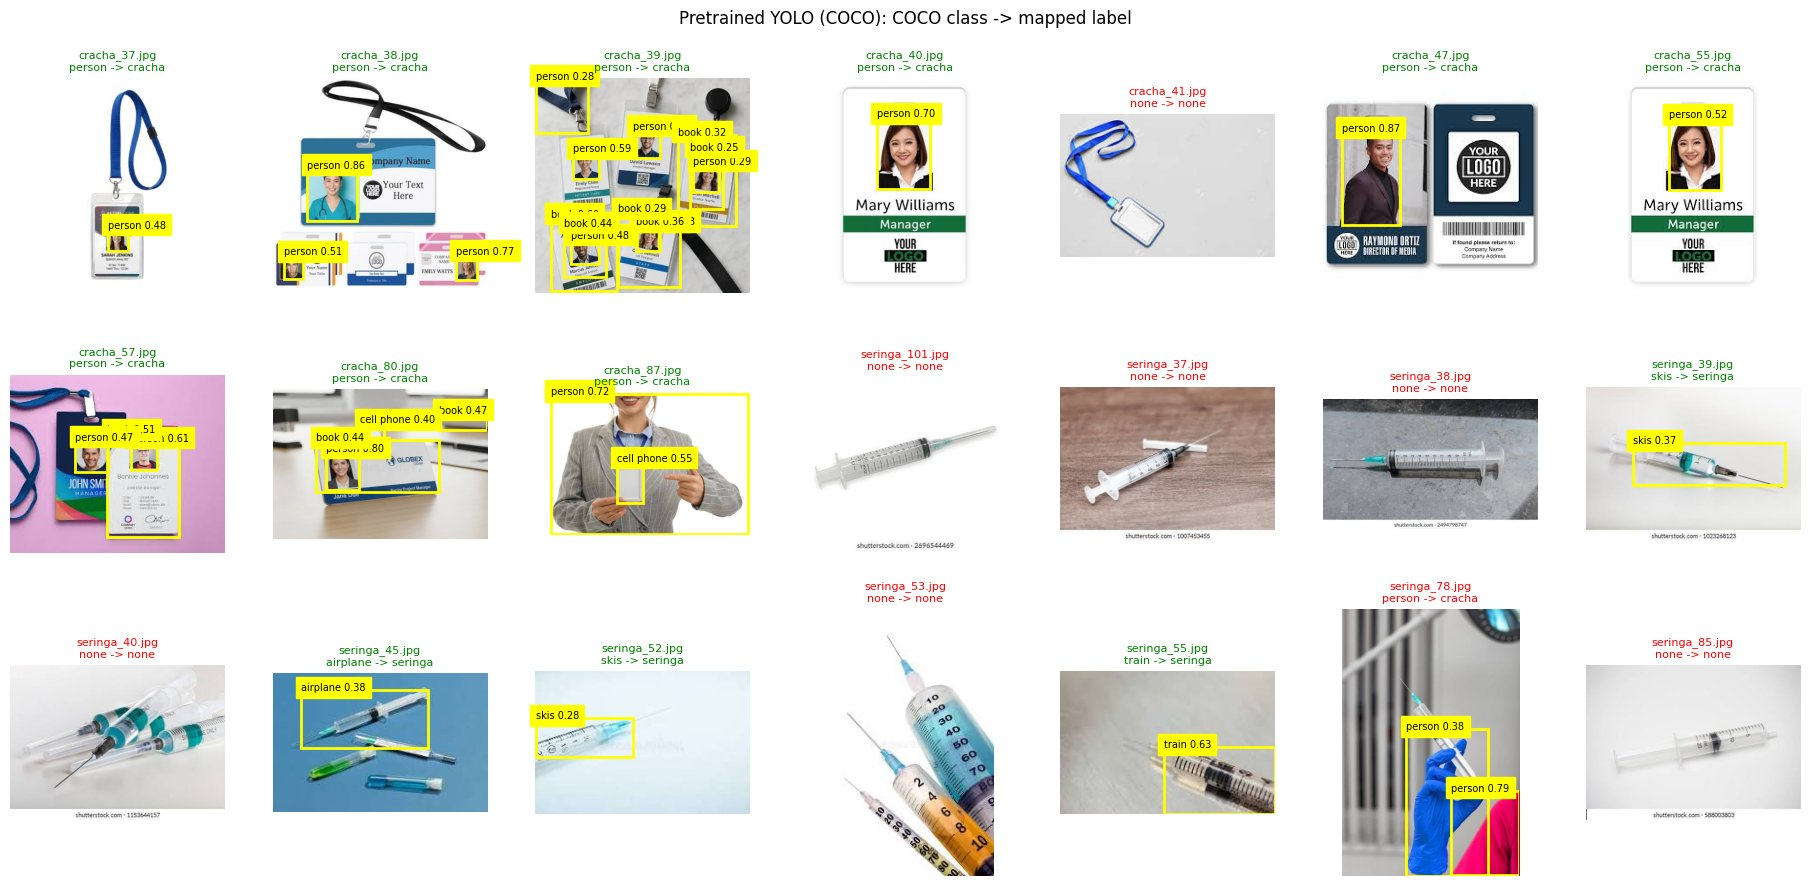

In [13]:
train_val = dataset[dataset.split != "test"]
train_val_top = [top_class(detect(coco_yolo, load_image(path))) for path in train_val.path]

votes = pd.crosstab(
    pd.Series(train_val_top, name="COCO class"),
    pd.Series(list(train_val.label), name="true label"),
)
mapping = {coco: votes.loc[coco].idxmax() for coco in votes.index if coco != "none"}

display(
    votes.assign(mapped_to=[mapping.get(name, "-") for name in votes.index])
    .sort_values(CLASSES, ascending=False)
    .head(12)
)

coco_preds = [mapping.get(name, "none") for name in coco_top]

results.append(evaluate("Pretrained YOLO (raw output)", coco_top, coco_ms))
results.append(evaluate("Pretrained YOLO + mapping", coco_preds, coco_ms))

display(pd.DataFrame(results).set_index("approach").round(3))
show_predictions(
    coco_preds,
    "Pretrained YOLO (COCO): COCO class -> mapped label",
    detections=coco_dets,
    captions=[f"{coco} -> {pred}" for coco, pred in zip(coco_top, coco_preds)],
)

Por fim, a localização: quantas caixas reais do teste são cobertas por alguma detecção, sem olhar
a classe.

In [14]:
def true_boxes(file, image):
    width, height = image.size
    boxes = []

    for box in read_boxes(DATA_DIR / "test" / "labels" / f"{Path(file).stem}.txt"):
        xc, yc, w, h = map(float, box[1:5])

        boxes.append((
            (xc - w / 2) * width,
            (yc - h / 2) * height,
            (xc + w / 2) * width,
            (yc + h / 2) * height,
        ))

    return boxes


def iou(a, b):
    inter_w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    inter_h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = inter_w * inter_h
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter

    return inter / union if union else 0.0


def localization_rate(all_detections):
    found = 0
    total = 0

    for file, image, detections in zip(test.file, test_images, all_detections):
        for box in true_boxes(file, image):
            total += 1
            found += any(iou(box, d[2]) >= 0.5 for d in detections)

    return found / total, total


models_to_check = [
    ("Custom YOLO (Entrega 1)", original_dets),
    ("Custom YOLO (fixed labels)", fixed_dets),
    ("Pretrained YOLO (COCO)", coco_dets),
]

for name, detections in models_to_check:
    rate, total = localization_rate(detections)
    print(f"{name:28} found {rate:.0%} of the {total} labeled boxes")

Custom YOLO (Entrega 1)      found 29% of the 14 labeled boxes
Custom YOLO (fixed labels)   found 43% of the 14 labeled boxes
Pretrained YOLO (COCO)       found 7% of the 14 labeled boxes


A saída direta nunca acerta. Com a regra, o YOLO padrão chega a 62%, mas por um atalho. Em 9 dos
10 crachás de teste, a detecção mais confiante é `person`, que é o rosto impresso no cartão. As 4
seringas que ele acerta aparecem como `skis`, `airplane` ou `train`.

Ele cobre só 1 das 14 caixas reais (7%). Ou seja, reconhece o que está no crachá, mas não o crachá.
Uma foto de crachá sem rosto, ou de alguém sem crachá, já quebraria a regra. Para comparar, o YOLO
com rótulos corrigidos localiza 43% das caixas.

## 5. CNN treinada do zero

A CNN classifica a imagem inteira, sem caixas, e começa com pesos aleatórios.

- **Arquitetura:** quatro blocos de convolução 3×3, normalização em lote, ReLU e *max pooling*,
  com 32, 64, 128 e 128 filtros. Depois vêm uma média global, *dropout* de 30% e a camada de saída
  com duas classes. São cerca de 240 mil parâmetros, contra 7 milhões do YOLOv5s.
- **Entrada:** imagens de 128 × 128 pixels.
- **Aumento de dados, só no treino:** recortes, espelhamento, rotação de até 15° e variação de
  brilho, contraste e saturação. Como a base é pequena, isso ajuda a rede a generalizar. Na
  validação e no teste, a imagem só é redimensionada.

Usamos PyTorch, a mesma biblioteca do YOLOv5. Assim, todas as abordagens rodam na mesma GPU e os
tempos podem ser comparados.

In [15]:
IMAGE_SIZE = 128

normalize = transforms.Normalize([0.5] * 3, [0.5] * 3)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.3, 0.3, 0.3),
    transforms.ToTensor(),
    normalize,
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    normalize,
])


def load_split(split):
    split_rows = dataset[dataset.split == split]
    images = []

    for path in split_rows.path:
        image = load_image(path)
        image.thumbnail((256, 256))
        images.append(image)

    targets = torch.tensor([CLASSES.index(label) for label in split_rows.label])
    return images, targets


train_images, train_targets = load_split("train")
val_images, val_targets = load_split("val")
val_batch = torch.stack([eval_transform(image) for image in val_images]).to(DEVICE)

print(f"Train: {len(train_images)} images | Validation: {len(val_images)} images")

Train: 161 images | Validation: 20 images


In [16]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


torch.manual_seed(SEED)

cnn = nn.Sequential(
    conv_block(3, 32),
    conv_block(32, 64),
    conv_block(64, 128),
    conv_block(128, 128),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Dropout(0.3),
    nn.Linear(128, len(CLASSES)),
).to(DEVICE)

print(f"{sum(p.numel() for p in cnn.parameters()):,} trainable parameters")

241,794 trainable parameters


O treino usa o otimizador AdamW, com lotes de 16 imagens e até 60 épocas. A cada época medimos a
perda na validação. Se ela passar 12 épocas sem melhorar, o treino para e voltamos aos pesos da
melhor época (*early stopping*).

In [17]:
EPOCHS = 60
PATIENCE = 12
BATCH_SIZE = 16

optimizer = torch.optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()

history = []
best_val_loss = float("inf")
best_weights = None
epochs_without_improvement = 0

sync()
start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    cnn.train()
    train_loss = 0.0

    for batch in torch.randperm(len(train_images)).split(BATCH_SIZE):
        if len(batch) < 2:
            continue

        x = torch.stack([train_transform(train_images[i]) for i in batch]).to(DEVICE)
        y = train_targets[batch].to(DEVICE)

        optimizer.zero_grad()
        loss = loss_fn(cnn(x), y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(batch)

    cnn.eval()

    with torch.no_grad():
        val_logits = cnn(val_batch)
        val_loss = loss_fn(val_logits, val_targets.to(DEVICE)).item()
        val_accuracy = (val_logits.argmax(1).cpu() == val_targets).float().mean().item()

    history.append({
        "epoch": epoch,
        "train_loss": train_loss / len(train_images),
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = {key: value.detach().clone() for key, value in cnn.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            break

sync()
cnn_train_seconds = time.perf_counter() - start

cnn.load_state_dict(best_weights)
history = pd.DataFrame(history).set_index("epoch")
best_epoch = history.val_loss.idxmin()

print(f"{len(history)} epochs in {cnn_train_seconds:.1f} s ({DEVICE_NAME})")
print(f"Best epoch: {best_epoch} (validation accuracy {history.val_accuracy[best_epoch]:.0%})")

21 epochs in 12.6 s (Tesla T4)
Best epoch: 9 (validation accuracy 75%)


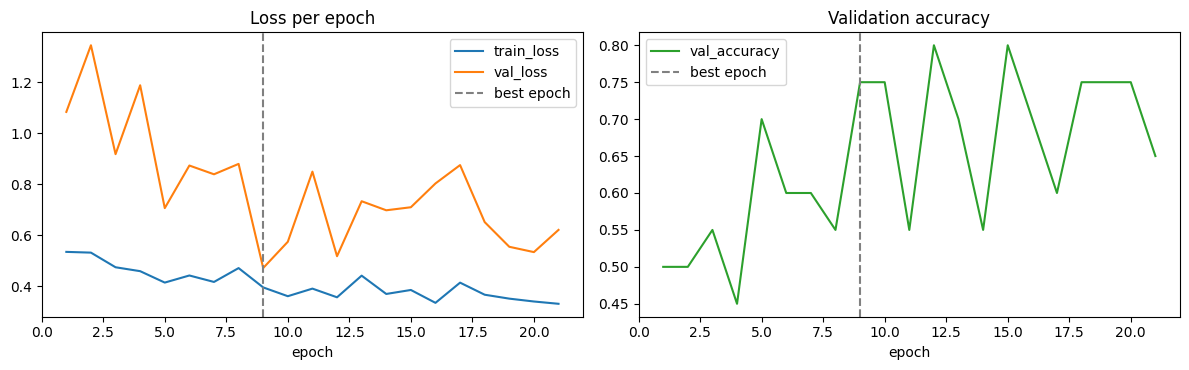

In [18]:
fig, (loss_ax, acc_ax) = plt.subplots(1, 2, figsize=(12, 3.8))

history[["train_loss", "val_loss"]].plot(ax=loss_ax, title="Loss per epoch")
history["val_accuracy"].plot(ax=acc_ax, title="Validation accuracy", color="tab:green")

for ax in (loss_ax, acc_ax):
    ax.axvline(best_epoch, color="gray", linestyle="--", label="best epoch")
    ax.legend()

plt.tight_layout()
plt.show()

,accuracy,recall_cracha,recall_seringa,no_answer,inference_ms
approach,,,,,
Custom YOLO (Entrega 1),0.143,0.3,0.000,0.714,14.186
Custom YOLO (fixed labels),0.524,0.7,0.364,0.429,10.461
Pretrained YOLO (raw output),0.000,0.0,0.000,0.333,11.066
Pretrained YOLO + mapping,0.619,0.9,0.364,0.333,11.066
CNN from scratch,0.857,0.9,0.818,0.000,2.224


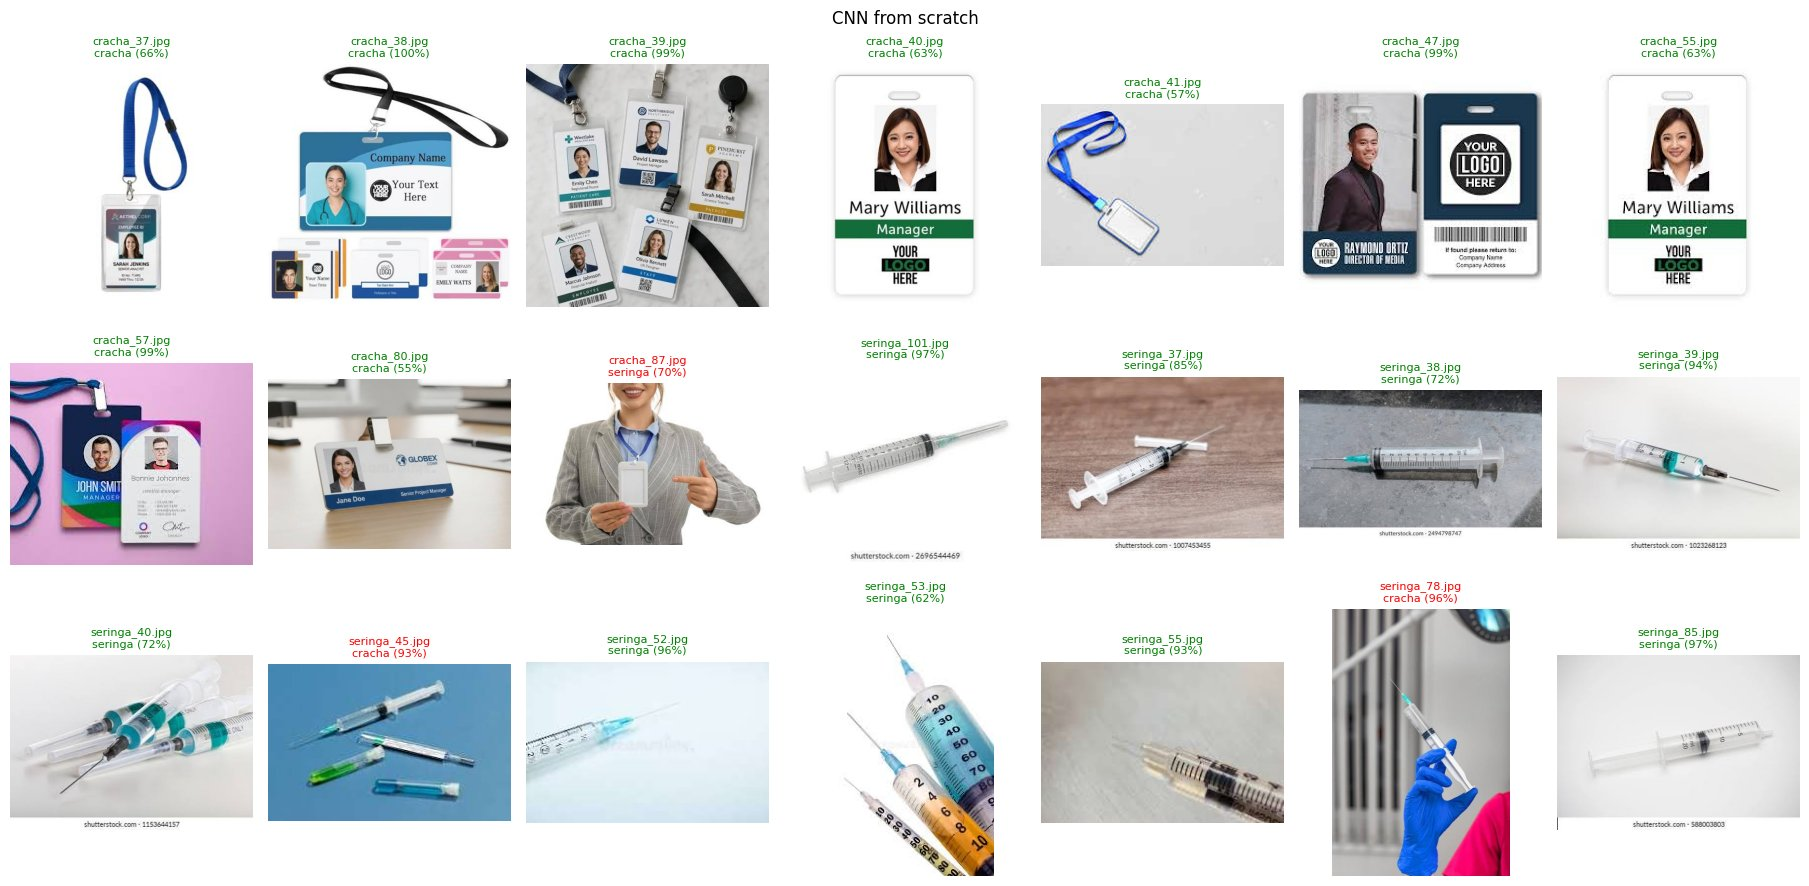

In [19]:
cnn.eval()


def classify(image):
    with torch.no_grad():
        x = eval_transform(image).unsqueeze(0).to(DEVICE)
        probs = cnn(x).softmax(1)[0]

    return CLASSES[int(probs.argmax())], float(probs.max())


cnn_outputs, cnn_ms = timed_predictions(classify, test_images)
cnn_preds = [label for label, _ in cnn_outputs]

results.append(evaluate("CNN from scratch", cnn_preds, cnn_ms))

display(pd.DataFrame(results).set_index("approach").round(3))
show_predictions(
    cnn_preds,
    "CNN from scratch",
    captions=[f"{label} ({prob:.0%})" for label, prob in cnn_outputs],
)

A CNN acerta 18 das 21 imagens (86%): 9 de 10 crachás e 9 de 11 seringas, e sempre dá uma
resposta. O treino parou na época 21, ficou com os pesos da época 9 e levou cerca de 13
segundos. Como não precisa de caixas, ela usa as 161 imagens de treino, inclusive as seringas que
ficaram sem rótulo para o YOLO.

Os três erros são fotos fora do padrão da base:

- `cracha_87`: uma pessoa de terno segurando o crachá, classificada como seringa;
- `seringa_78`: uma mão de luva segurando a seringa, classificada como crachá;
- `seringa_45`: várias seringas sobre fundo azul, classificada como crachá.

A rede aprende também o contexto da foto, e não só o objeto.

## 6. Comparação

A tabela junta os critérios. Medimos os tempos de inferência aqui, na mesma GPU. O tempo de treino
do YOLO da Entrega 1 vem do log daquela entrega, também numa T4; o do YOLO corrigido e o da CNN
foram medidos neste notebook.

In [20]:
cnn_path = WORK_DIR / "cnn.pt"
torch.save(cnn.state_dict(), cnn_path)


def size_mb(path):
    return Path(path).stat().st_size / 1e6


details = {
    "Custom YOLO (Entrega 1)": (
        "box per object",
        "~2.8 min (50 epochs, T4, Entrega 1)",
        size_mb(ORIGINAL_WEIGHTS),
    ),
    "Custom YOLO (fixed labels)": (
        "box per object",
        f"{fixed_train_seconds / 60:.1f} min ({YOLO_EPOCHS} epochs, {DEVICE_NAME})",
        size_mb(FIXED_WEIGHTS),
    ),
    "Pretrained YOLO (raw output)": ("none", "none", size_mb(COCO_WEIGHTS)),
    "Pretrained YOLO + mapping": ("label per image (mapping only)", "none", size_mb(COCO_WEIGHTS)),
    "CNN from scratch": (
        "label per image",
        f"{cnn_train_seconds:.0f} s ({DEVICE_NAME})",
        size_mb(cnn_path),
    ),
}

comparison = pd.DataFrame(results).set_index("approach")
comparison.insert(0, "labeling", [details[name][0] for name in comparison.index])
comparison.insert(1, "training", [details[name][1] for name in comparison.index])
comparison["model_mb"] = [details[name][2] for name in comparison.index]

comparison.round(3)

,labeling,training,accuracy,recall_cracha,recall_seringa,no_answer,inference_ms,model_mb
approach,,,,,,,,
Custom YOLO (Entrega 1),box per object,"~2.8 min (50 epochs, T4, Entrega 1)",0.143,0.3,0.000,0.714,14.186,14.448
Custom YOLO (fixed labels),box per object,"2.6 min (50 epochs, Tesla T4)",0.524,0.7,0.364,0.429,10.461,14.448
Pretrained YOLO (raw output),none,none,0.000,0.0,0.000,0.333,11.066,14.808
Pretrained YOLO + mapping,label per image (mapping only),none,0.619,0.9,0.364,0.333,11.066,14.808
CNN from scratch,label per image,13 s (Tesla T4),0.857,0.9,0.818,0.000,2.224,0.978


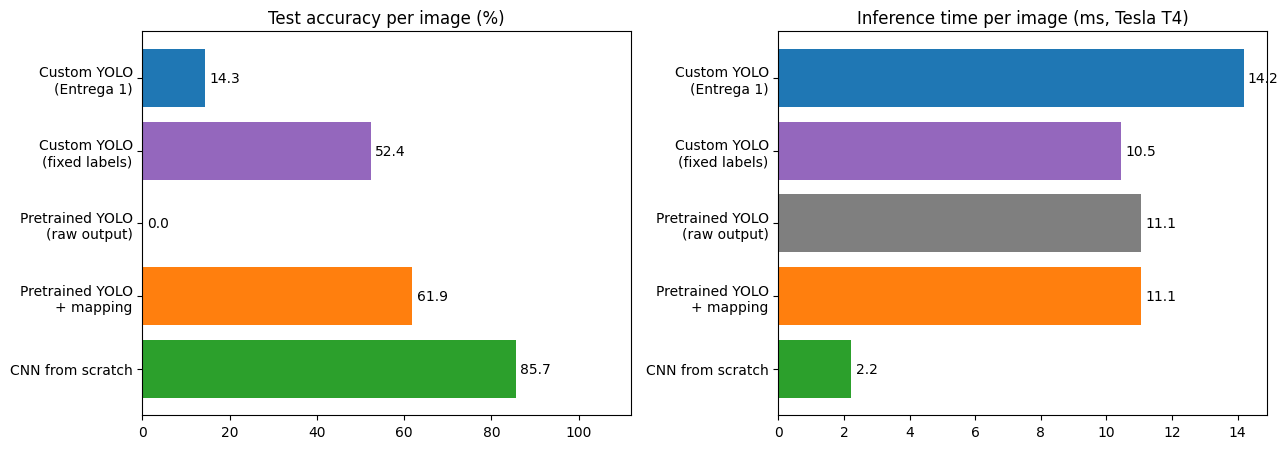

In [21]:
colors = {
    "Custom YOLO (Entrega 1)": "tab:blue",
    "Custom YOLO (fixed labels)": "tab:purple",
    "Pretrained YOLO (raw output)": "tab:gray",
    "Pretrained YOLO + mapping": "tab:orange",
    "CNN from scratch": "tab:green",
}
bar_colors = [colors[name] for name in comparison.index]
bar_names = [name.replace(" (", "\n(").replace(" + ", "\n+ ") for name in comparison.index]

fig, (acc_ax, time_ax) = plt.subplots(1, 2, figsize=(13, 4.6))

acc_ax.barh(bar_names, comparison.accuracy * 100, color=bar_colors)
acc_ax.set(title="Test accuracy per image (%)", xlim=(0, 112))

time_ax.barh(bar_names, comparison.inference_ms, color=bar_colors)
time_ax.set(title=f"Inference time per image (ms, {DEVICE_NAME})")

for ax in (acc_ax, time_ax):
    ax.invert_yaxis()
    ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)

plt.tight_layout()
plt.show()

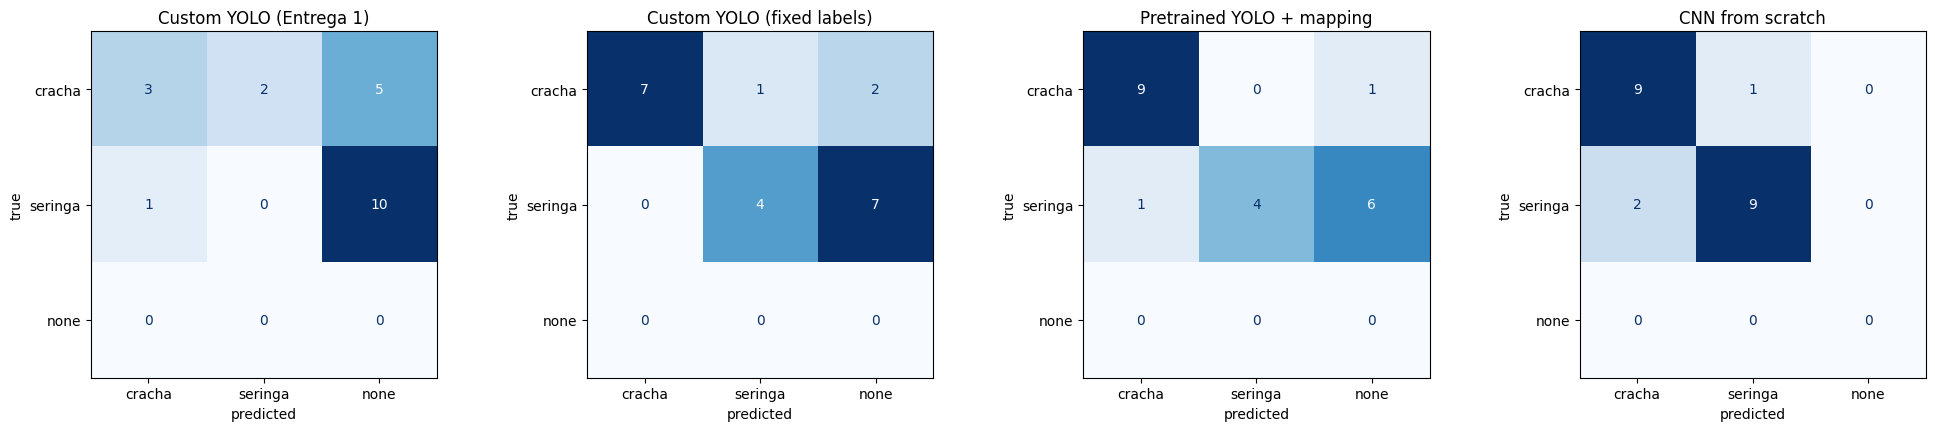

In [22]:
matrix_labels = CLASSES + ["none"]

models_to_compare = [
    ("Custom YOLO (Entrega 1)", original_preds),
    ("Custom YOLO (fixed labels)", fixed_preds),
    ("Pretrained YOLO + mapping", coco_preds),
    ("CNN from scratch", cnn_preds),
]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))

for ax, (name, preds) in zip(axes, models_to_compare):
    matrix = confusion_matrix(test_labels, preds, labels=matrix_labels)
    ConfusionMatrixDisplay(matrix, display_labels=matrix_labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set(title=name, xlabel="predicted", ylabel="true")

plt.tight_layout()
plt.show()

## 7. Avaliação crítica

### Facilidade de uso e integração

O YOLO padrão é o mais fácil: três linhas carregam o modelo, sem dados e sem treino. O problema é
que ele não conhece crachás nem seringas. A regra de tradução depende de um atalho, o rosto no
crachá, que não se sustenta fora desta base.

O YOLO customizado dá mais trabalho antes do treino:

- desenhar uma caixa em cada objeto no Make Sense;
- montar o `data.yaml`;
- treinar com GPU.

A seção 3.1 mostra o risco dessa etapa: erros de rotulagem, que o treino não acusa, derrubaram a
acurácia de 52% para 14%. Depois de pronto, ele se integra como o YOLO padrão (mesmo código e um
`best.pt` de 14,4 MB) e informa onde está cada objeto e quantos há.

A CNN tem a rotulagem mais simples, só a classe de cada imagem. Em compensação, tivemos que
escrever a arquitetura, o aumento de dados e o laço de treino. Ela diz qual objeto aparece, mas não
onde nem quantos, e parte do princípio de que há um objeto por imagem.

### Precisão

Com 21 imagens de teste, cada imagem vale 4,8 pontos de acurácia.

| Abordagem | Acurácia | mAP50 no teste | Observação |
|---|---|---|---|
| CNN do zero | 86% | não se aplica | a única que sempre responde |
| YOLO padrão + regra | 62% | não se aplica | acerta pelo atalho do rosto e não localiza o crachá |
| YOLO com rótulos corrigidos | 52% | 0,50 | quase não troca as classes, mas fica sem resposta em várias seringas |
| YOLO da Entrega 1 | 14% | 0,21 | prejudicado pelos rótulos trocados |

A vantagem da CNN sobre o YOLO corrigido, de 7 imagens, é real. Mas a comparação favorece a CNN:
ela só precisa dizer qual objeto aparece, enquanto o YOLO também precisa encontrá-lo com confiança
acima do limiar.

### Tempo de treinamento

- **YOLO padrão:** não tem treino.
- **YOLO customizado:** levou 2,1 minutos de GPU para 50 épocas (2,6 com a preparação), perto dos
  2,8 minutos da Entrega 1. O custo maior, porém, é o tempo de rotular as caixas.
- **CNN:** treinou em cerca de 13 segundos, por ser pequena e usar imagens de 128 px.

### Tempo de inferência

Os YOLOs levaram entre 10,5 e 14,2 ms por imagem, de 70 a 95 imagens por segundo, o suficiente
para vídeo em tempo real. Como a arquitetura é a mesma, customizar não muda a velocidade; a
diferença entre eles é variação da medição.

A CNN levou 2,2 ms, de cinco a seis vezes menos, e o modelo tem 1 MB, contra 14,4 MB do YOLO.

### Limitações

- **Teste pequeno:** são só 21 imagens, então diferenças de uma ou duas imagens não são
  conclusivas.
- **Variação entre execuções:** a CNN e o YOLO corrigido foram treinados uma vez neste notebook.
  Numa execução anterior, o YOLO corrigido teve 57% de acurácia e mAP50 de 0,43; nesta, 52% e 0,50.
  A ordem entre as abordagens, porém, se manteve.
- **Base corrigida desbalanceada:** tem 78 crachás e só 32 seringas com caixa.
- **Marca d'água:** muitas fotos de seringa vêm de banco de imagens e têm a marca `shutterstock`
  no rodapé. A CNN acertou as 6 seringas de teste com essa marca e só 3 das 5 sem ela. Parte do
  resultado pode vir desse detalhe, e não da seringa.
- **Só a detecção mais confiante:** a acurácia por imagem ignora as outras caixas do YOLO.

### Conclusão

Para classificar fotos com um único objeto, como na triagem de imagens enviadas por operadores, a
CNN foi a melhor opção nesta base:

- mais precisa;
- de cinco a seis vezes mais rápida;
- 14 vezes menor;
- treino de segundos e rotulagem simples.

Antes de usar em produção, ela precisa ser testada com fotos reais, sem marca d'água.

Para localizar ou contar objetos, como o crachá na catraca ou as seringas na bancada, o caminho
continua sendo o YOLO customizado. O problema da Entrega 1 estava na rotulagem, não no modelo: só
corrigir os rótulos quase quadruplicou a acurácia e mais que dobrou o mAP50. O próximo passo é
rotular no Make Sense as 62 seringas sem caixa (49 de treino, 6 de validação e 7 de teste) e
treinar de novo.

O YOLO padrão não serve para objetos fora das 80 classes do COCO. Aqui, ele só acertou por
acidente.